# BrickView: Data preparation, SQL analysis and EDA

This notebook walks through the whole project:

1. **Raw data**: load the five provided files and profile them
2. **Cleaning**: what `src/clean.py` changes, and the data-quality issues found
3. **Database**: the normalised SQLite schema, indexes and views (`sql/schema.sql`)
4. **SQL analysis**: all 30 business questions from the brief (`sql/queries.sql`), each with its result and a written answer
5. **Key insights**

Run `python pipeline.py` first (the repository already ships the built database). Charts are saved to `reports/figures/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import config
from src import clean, db

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 20)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "figure.dpi": 110})
BRICK = "#b4532a"

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

## 1. Raw data

In [2]:
raw = {}
for name, file in config.RAW_FILES.items():
    path = config.RAW_DIR / file
    raw[name] = pd.read_csv(path) if path.suffix == ".csv" else pd.json_normalize(json.loads(path.read_text()))
pd.DataFrame({name: {"file": config.RAW_FILES[name], "rows": len(df), "columns": df.shape[1],
                     "missing values": int(df.isna().sum().sum()), "duplicate rows": int(df.duplicated().sum())}
              for name, df in raw.items()}).T

,file,rows,columns,missing values,duplicate rows
listings,listings_final_expanded.json,21200,9,0,0
property_attributes,property_attributes_final_expanded.json,21200,13,0,0
agents,agents_cleaned.json,50,9,0,0
sales,sales_cleaned.csv,720,4,0,0
buyers,buyers_cleaned.json,20000,7,9966,0


In [3]:
for name, df in raw.items():
    print(f"--- {name}: {list(df.columns)}")
raw["listings"].head()

--- listings: ['Listing_ID', 'City', 'Property_Type', 'Price', 'Sqft', 'Date_Listed', 'Agent_ID', 'Latitude', 'Longitude']
--- property_attributes: ['attribute_id', 'listing_id', 'bedrooms', 'bathrooms', 'floor_number', 'total_floors', 'year_built', 'is_rented', 'tenant_count', 'furnishing_status', 'metro_distance_km', 'parking_available', 'power_backup']
--- agents: ['Agent_ID', 'Name', 'Phone', 'Email', 'commission_rate', 'deals_closed', 'rating', 'experience_years', 'avg_closing_days']
--- sales: ['Listing_ID', 'Sale_Price', 'Date_Sold', 'Days_on_Market']
--- buyers: ['buyer_id', 'sale_id', 'buyer_type', 'payment_mode', 'loan_taken', 'loan_provider', 'loan_amount']


,Listing_ID,City,Property_Type,Price,Sqft,Date_Listed,Agent_ID,Latitude,Longitude
0,L00001,New York,Apartment,"1,655,144.01","2,753.01",2023-05-06,A0015,33.97,-69.86
1,L00002,Los Angeles,Apartment,"1,519,141.00","4,966.99",2023-02-14,A0038,42.55,-90.28
2,L00003,Houston,Apartment,"162,489.00","1,267.00",2023-04-22,A0015,28.73,-115.95
3,L00004,Phoenix,Apartment,"1,277,015.98","2,128.01",2024-01-02,A0042,26.40,-74.77
4,L00005,Phoenix,Townhouse,"562,297.01","4,179.00",2023-10-29,A0018,39.43,-83.92


In [4]:
raw["listings"].describe().T

,count,mean,std,min,25%,50%,75%,max
Price,"21,200.00","2,452,708.33","1,419,864.49","100,027.13","1,216,681.26","2,383,802.92","3,679,127.06","4,999,863.52"
Sqft,"21,200.00","5,113.38","2,737.68",500.01,"2,768.28","4,974.84","7,488.90","9,999.59"
Latitude,"21,200.00",37.01,6.93,25.01,30.97,37.06,42.95,49.00
Longitude,"21,200.00",-96.10,16.73,-125.00,-110.67,-96.16,-81.73,-67.00


### Data-quality checks on the raw files

In [5]:
L, A, S, B, G = (raw[k] for k in ["listings", "property_attributes", "sales", "buyers", "agents"])
merged = S.merge(L, on="Listing_ID")
gap = (pd.to_datetime(merged["Date_Sold"]) - pd.to_datetime(merged["Date_Listed"])).dt.days
checks = {
    "sales whose listing is missing": (~S["Listing_ID"].isin(L["Listing_ID"])).sum(),
    "listings whose agent is missing": (~L["Agent_ID"].isin(G["Agent_ID"])).sum(),
    "buyers.sale_id values that are listing IDs": B["sale_id"].str.startswith("L").sum(),
    "distinct sales referenced by buyers": B["sale_id"].nunique(),
    "max |days_on_market - (date_sold - date_listed)|": round((merged["Days_on_Market"] - gap).abs().max(), 3),
    "floor_number > total_floors": (A["floor_number"] > A["total_floors"]).sum(),
    "not rented but tenant_count > 0": ((~A["is_rented"]) & (A["tenant_count"] > 0)).sum(),
    "rented but tenant_count = 0": ((A["is_rented"]) & (A["tenant_count"] == 0)).sum(),
    "highest sold listing number": S["Listing_ID"].str[1:].astype(int).max(),
}
pd.Series(checks, name="value").to_frame()

,value
sales whose listing is missing,0.00
listings whose agent is missing,0.00
buyers.sale_id values that are listing IDs,"20,000.00"
distinct sales referenced by buyers,720.00
max |days_on_market - (date_sold - date_listed)|,0.03
floor_number > total_floors,255.00
not rented but tenant_count > 0,467.00
rented but tenant_count = 0,"2,067.00"
highest sold listing number,"1,196.00"


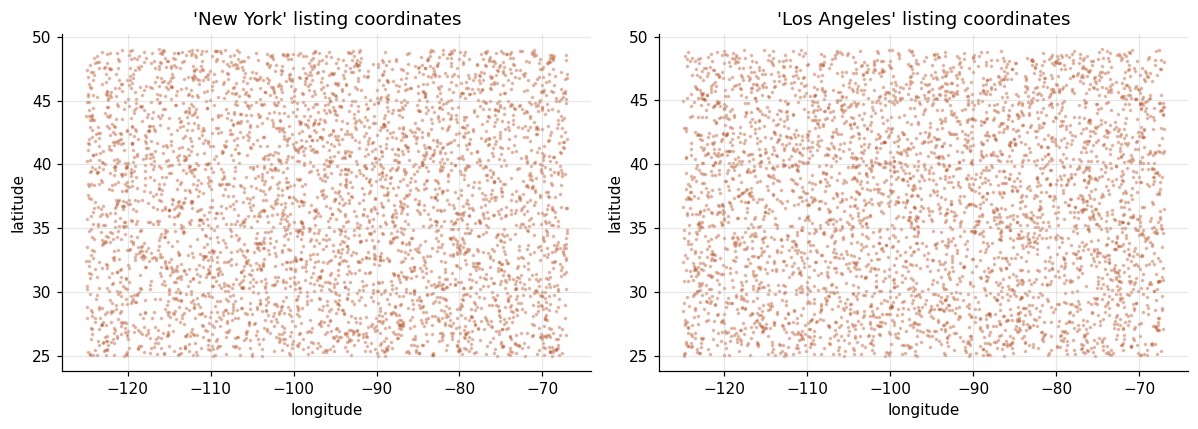

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, city in zip(axes, ["New York", "Los Angeles"]):
    sub = L[L["City"] == city]
    ax.scatter(sub["Longitude"], sub["Latitude"], s=2, alpha=.3, color=BRICK)
    ax.set_title(f"'{city}' listing coordinates"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
save("raw_coordinates_by_city")

In [7]:
L["population"] = (L["Listing_ID"].str[1:].astype(int) <= 1200).map({True: "L00001-L01200", False: "L01201-L21200"})
L.groupby("population").agg(listings=("Listing_ID", "size"), min_price=("Price", "min"),
                            max_price=("Price", "max"), avg_price=("Price", "mean"), avg_sqft=("Sqft", "mean"))

,listings,min_price,max_price,avg_price,avg_sqft
population,,,,,
L00001-L01200,1200,"101,767.99","1,997,459.01","1,070,132.69","2,809.40"
L01201-L21200,20000,"100,027.13","4,999,863.52","2,535,662.87","5,251.61"


In [8]:
loans = B[B["loan_taken"]].merge(S, left_on="sale_id", right_on="Listing_ID")
print(f"buyer records per sale: {len(B) / B['sale_id'].nunique():.1f}")
print(f"loans larger than the sale price: {(loans['loan_amount'] > loans['Sale_Price']).mean():.1%}")

buyer records per sale: 27.8
loans larger than the sale price: 93.3%


**What the checks show**

- Keys are consistent: every sale, attribute row and buyer points to an existing listing, and every listing to an existing agent.
- `buyers.sale_id` actually stores **listing IDs** (e.g. `L01179`). The pipeline maps them to the real `sales.sale_id`.
- There are **20,000 buyer records for 720 sales** (about 28 per sale), and 93% of loans exceed the sale price. Buyer analysis is therefore done on *buyer records*, and loan amounts are treated as unrealistic.
- `Days_on_Market` is a float with tiny noise; it equals the date gap to within 0.03 days, so it is stored as whole days.
- **Coordinates are random points across the continental US** for every city (see the plot), so they can't be used for city-level geography.
- **Two populations of listings:** only L00001-L01200 have sales. They are priced $0.1M-2M; the other 20,000 listings run to $5M and none are sold.
- 255 rows have `floor_number > total_floors` (swapped back). Rented/tenant inconsistencies are flagged but left as given.

## 2. Cleaning

In [9]:
tables, log = clean.clean_all()
log

,table,step,rows_affected
0,agents,drop duplicate agent_id,0
1,agents,"standardise column names, numeric types, lower...",50
2,listings,drop duplicate listing_id,0
3,listings,"round price / area to 2 dp, coordinates to 6 d...",21200
4,listings,drop rows missing id / city / type / price / date,0
5,listings,set agent_id NULL where the agent does not exist,0
6,property_attributes,drop duplicate listing_id,0
7,property_attributes,booleans -> 0/1 integers,21200
8,property_attributes,swap floor_number / total_floors where floor >...,255
9,property_attributes,drop rows whose listing_id is not in listings,0


In [10]:
pd.DataFrame({name: {"rows": len(df), "columns": ", ".join(df.columns)} for name, df in tables.items()}).T

,rows,columns
agents,50,"agent_id, name, phone, email, commission_rate,..."
listings,21200,"listing_id, city, property_type, price, area_s..."
property_attributes,21200,"attribute_id, listing_id, bedrooms, bathrooms,..."
sales,720,"sale_id, listing_id, sale_price, date_sold, da..."
buyers,20000,"buyer_id, sale_id, buyer_type, payment_mode, l..."


## 3. Database

`pipeline.py` writes the cleaned tables to `data/processed/*.csv` and loads them into `db/brickview.db` using
`sql/schema.sql`: five tables with primary keys, foreign keys (`ON DELETE CASCADE / SET NULL`), `UNIQUE` one-to-one
links (one attribute row and at most one sale per listing), `CHECK` constraints on ranges and categories,
10 indexes on join and filter columns, and 6 reporting views.

In [11]:
objects = db.query("SELECT type, name, tbl_name FROM sqlite_master WHERE name NOT LIKE 'sqlite_%' ORDER BY type, name")
counts = {t: db.query(f"SELECT COUNT(*) n FROM {t}")["n"][0] for t in config.TABLE_ORDER}
print(counts, db.integrity_report())
objects

{'agents': np.int64(50), 'listings': np.int64(21200), 'property_attributes': np.int64(21200), 'sales': np.int64(720), 'buyers': np.int64(20000)} {'foreign_key_violations': 0, 'integrity_check': 'ok'}


,type,name,tbl_name
0,index,idx_attr_furnishing,property_attributes
1,index,idx_buyers_sale,buyers
2,index,idx_buyers_type,buyers
3,index,idx_listings_agent,listings
4,index,idx_listings_city,listings
5,index,idx_listings_city_type,listings
6,index,idx_listings_date,listings
7,index,idx_listings_price,listings
8,index,idx_listings_type,listings
9,index,idx_sales_date,sales


## 4. SQL analysis: the 30 business questions

Each query is read from `sql/queries.sql` (the same file the Streamlit **SQL Insights** page uses).

In [12]:
QUERIES = {q["id"]: q for q in db.load_queries()}

def run(qid, show_sql=True):
    q = QUERIES[qid]
    print(f"{qid}. {q['question']}\n")
    if show_sql:
        print(q["sql"], "\n")
    return db.query(q["sql"])

### Property & Pricing

#### Q01. What is the average listing price by city?

In [13]:
r = run("Q01")
r

Q01. What is the average listing price by city?

SELECT city,
       COUNT(*)              AS listings,
       ROUND(AVG(price), 2)  AS avg_list_price
FROM listings
GROUP BY city
ORDER BY avg_list_price DESC 



,city,listings,avg_list_price
0,New York,4269,"2,493,319.74"
1,Phoenix,4229,"2,459,961.76"
2,Los Angeles,4318,"2,442,418.31"
3,Houston,4091,"2,436,811.00"
4,Chicago,4293,"2,430,677.90"


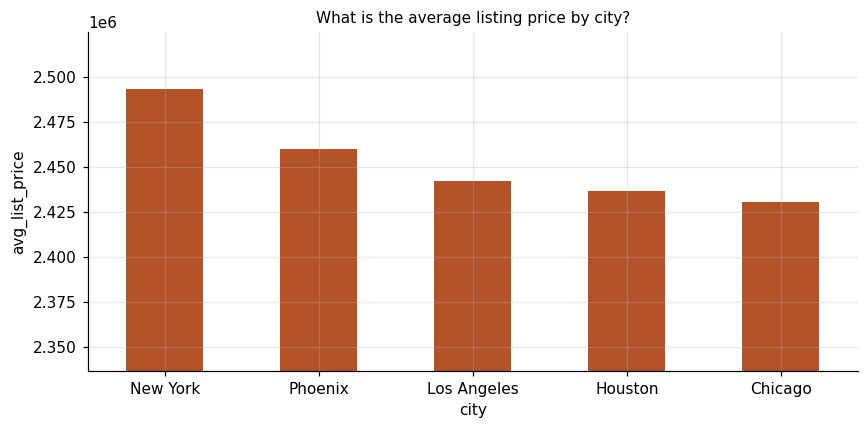

In [14]:
ax = r.plot.bar(x="city", y="avg_list_price", color=BRICK, legend=False, rot=0)
lo, hi = r["avg_list_price"].min(), r["avg_list_price"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("What is the average listing price by city?", fontsize=10); ax.set_ylabel("avg_list_price")
save("q01_avg_price_by_city")

**Answer:** New York is the priciest city ($2.49M average) and Chicago the cheapest ($2.43M), a spread of only 2.6%.

#### Q02. What is the average price per square foot by property type?

In [15]:
r = run("Q02")
r

Q02. What is the average price per square foot by property type?

SELECT property_type,
       COUNT(*)                                AS listings,
       ROUND(AVG(price / area_sqft), 2)        AS avg_price_per_sqft,
       ROUND(SUM(price) / SUM(area_sqft), 2)   AS weighted_price_per_sqft
FROM listings
GROUP BY property_type
ORDER BY avg_price_per_sqft DESC 



,property_type,listings,avg_price_per_sqft,weighted_price_per_sqft
0,House,5330,796.04,484.31
1,Apartment,5335,792.20,479.84
2,Townhouse,5172,789.75,484.10
3,Condo,5363,754.68,470.73


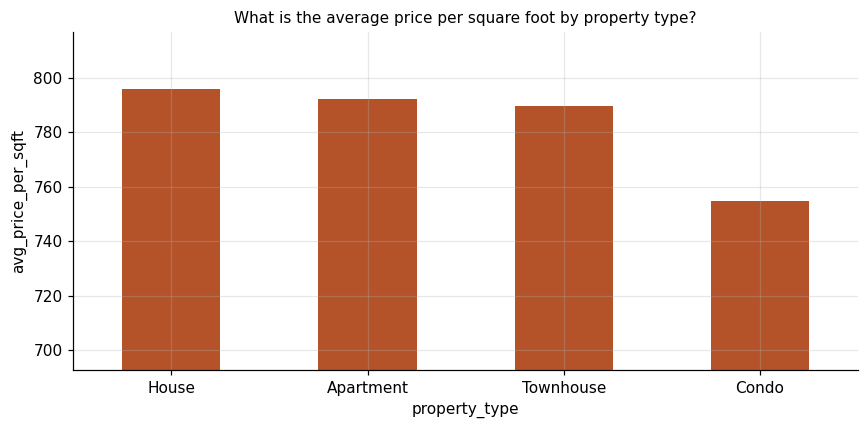

In [16]:
ax = r.plot.bar(x="property_type", y="avg_price_per_sqft", color=BRICK, legend=False, rot=0)
lo, hi = r["avg_price_per_sqft"].min(), r["avg_price_per_sqft"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("What is the average price per square foot by property type?", fontsize=10); ax.set_ylabel("avg_price_per_sqft")
save("q02_price_per_sqft_by_type")

**Answer:** Houses have the highest price per sq ft ($796) and condos the lowest ($755). The plain average is far above the size-weighted figure (~$480) because small units carry very high per-sq-ft prices.

#### Q03. How does furnishing status impact property prices?

In [17]:
r = run("Q03")
r

Q03. How does furnishing status impact property prices?

SELECT pa.furnishing_status,
       COUNT(*)                                 AS listings,
       ROUND(AVG(l.price), 2)                   AS avg_list_price,
       ROUND(AVG(l.price / l.area_sqft), 2)     AS avg_price_per_sqft
FROM listings l
JOIN property_attributes pa ON pa.listing_id = l.listing_id
GROUP BY pa.furnishing_status
ORDER BY avg_list_price DESC 



,furnishing_status,listings,avg_list_price,avg_price_per_sqft
0,Furnished,6977,"2,463,539.06",792.41
1,Semi-Furnished,7013,"2,461,192.65",780.41
2,Unfurnished,7210,"2,433,975.10",776.64


**Answer:** Furnished homes list about 1.2% higher than unfurnished ones: a small premium.

#### Q04. Do properties closer to metro stations command higher prices?

In [18]:
r = run("Q04")
r

Q04. Do properties closer to metro stations command higher prices?

SELECT CASE WHEN pa.metro_distance_km < 2  THEN '1. Under 2 km'
            WHEN pa.metro_distance_km < 5  THEN '2. 2-5 km'
            WHEN pa.metro_distance_km < 10 THEN '3. 5-10 km'
            ELSE '4. 10 km+' END                AS metro_distance,
       COUNT(*)                                 AS listings,
       ROUND(AVG(l.price), 2)                   AS avg_list_price,
       ROUND(AVG(l.price / l.area_sqft), 2)     AS avg_price_per_sqft
FROM listings l
JOIN property_attributes pa ON pa.listing_id = l.listing_id
GROUP BY metro_distance
ORDER BY metro_distance 



,metro_distance,listings,avg_list_price,avg_price_per_sqft
0,1. Under 2 km,2888,"2,376,124.22",763.46
1,2. 2-5 km,4419,"2,407,369.68",763.84
2,3. 5-10 km,7221,"2,442,765.21",787.27
3,4. 10 km+,6672,"2,526,648.02",799.76


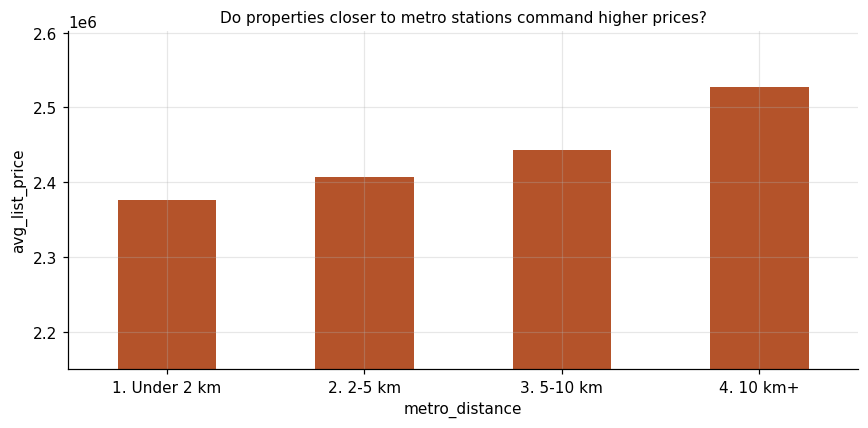

In [19]:
ax = r.plot.bar(x="metro_distance", y="avg_list_price", color=BRICK, legend=False, rot=0)
lo, hi = r["avg_list_price"].min(), r["avg_list_price"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("Do properties closer to metro stations command higher prices?", fontsize=10); ax.set_ylabel("avg_list_price")
save("q04_metro_distance_price")

**Answer:** No metro premium. Listings within 2 km of a metro average $2.38M, those 10 km+ away $2.53M. Distance does not raise prices in this data.

#### Q05. Are rented properties priced differently from non-rented ones?

In [20]:
r = run("Q05")
r

Q05. Are rented properties priced differently from non-rented ones?

SELECT CASE pa.is_rented WHEN 1 THEN 'Rented' ELSE 'Not rented' END AS rental_status,
       COUNT(*)                                 AS listings,
       ROUND(AVG(l.price), 2)                   AS avg_list_price,
       ROUND(AVG(l.price / l.area_sqft), 2)     AS avg_price_per_sqft
FROM listings l
JOIN property_attributes pa ON pa.listing_id = l.listing_id
GROUP BY pa.is_rented
ORDER BY avg_list_price DESC 



,rental_status,listings,avg_list_price,avg_price_per_sqft
0,Rented,10578,"2,457,184.90",789.36
1,Not rented,10622,"2,448,250.30",776.81


**Answer:** Rented and non-rented properties are priced almost the same (+0.4% for rented).

#### Q06. How do bedrooms and bathrooms affect pricing?

In [21]:
r = run("Q06")
r

Q06. How do bedrooms and bathrooms affect pricing?

SELECT pa.bedrooms,
       pa.bathrooms,
       COUNT(*)                 AS listings,
       ROUND(AVG(l.price), 2)   AS avg_list_price
FROM listings l
JOIN property_attributes pa ON pa.listing_id = l.listing_id
GROUP BY pa.bedrooms, pa.bathrooms
ORDER BY pa.bedrooms, pa.bathrooms 



,bedrooms,bathrooms,listings,avg_list_price
0,1,1,1040,"2,434,001.41"
1,1,2,1047,"2,509,474.77"
2,1,3,1028,"2,459,032.59"
3,1,4,1094,"2,455,532.96"
4,2,1,1068,"2,455,735.36"
5,2,2,1127,"2,378,687.66"
6,2,3,1060,"2,482,618.93"
7,2,4,1021,"2,555,766.23"
8,3,1,1032,"2,426,007.97"
9,3,2,1064,"2,409,122.73"


**Answer:** Bedroom and bathroom counts barely move the average price (every group sits between about $2.38M and $2.56M): size is not priced in this data set.

#### Q07. Do properties with parking and power backup sell at higher prices?

In [22]:
r = run("Q07")
r

Q07. Do properties with parking and power backup sell at higher prices?

SELECT CASE WHEN pa.parking_available = 1 AND pa.power_backup = 1 THEN 'Parking + power backup'
            WHEN pa.parking_available = 1 THEN 'Parking only'
            WHEN pa.power_backup = 1 THEN 'Power backup only'
            ELSE 'Neither' END                  AS amenities,
       COUNT(*)                                 AS listings,
       ROUND(AVG(l.price), 2)                   AS avg_list_price,
       COUNT(s.sale_id)                         AS sales,
       ROUND(AVG(s.sale_price), 2)              AS avg_sale_price
FROM listings l
JOIN property_attributes pa ON pa.listing_id = l.listing_id
LEFT JOIN sales s           ON s.listing_id  = l.listing_id
GROUP BY amenities
ORDER BY avg_sale_price DESC 



,amenities,listings,avg_list_price,sales,avg_sale_price
0,Parking + power backup,5243,"2,465,651.62",170,"1,092,597.11"
1,Parking only,5383,"2,462,363.80",198,"1,085,159.68"
2,Power backup only,5166,"2,446,292.59",170,"1,085,149.05"
3,Neither,5408,"2,436,677.75",182,"1,048,102.17"


**Answer:** Homes with both parking and power backup sold for the most ($1.09M average), about 4% more than homes with neither ($1.05M).

#### Q08. How does year built influence listing price?

In [23]:
r = run("Q08")
r

Q08. How does year built influence listing price?

SELECT pa.year_built,
       COUNT(*)                 AS listings,
       ROUND(AVG(l.price), 2)   AS avg_list_price
FROM listings l
JOIN property_attributes pa ON pa.listing_id = l.listing_id
GROUP BY pa.year_built
ORDER BY pa.year_built 



,year_built,listings,avg_list_price
0,1990,607,"2,533,791.60"
1,1991,605,"2,573,916.58"
2,1992,574,"2,594,651.56"
3,1993,548,"2,611,748.25"
4,1994,608,"2,571,504.92"
5,1995,608,"2,434,727.72"
6,1996,617,"2,391,385.75"
7,1997,610,"2,493,105.20"
8,1998,649,"2,398,158.87"
9,1999,655,"2,498,402.48"


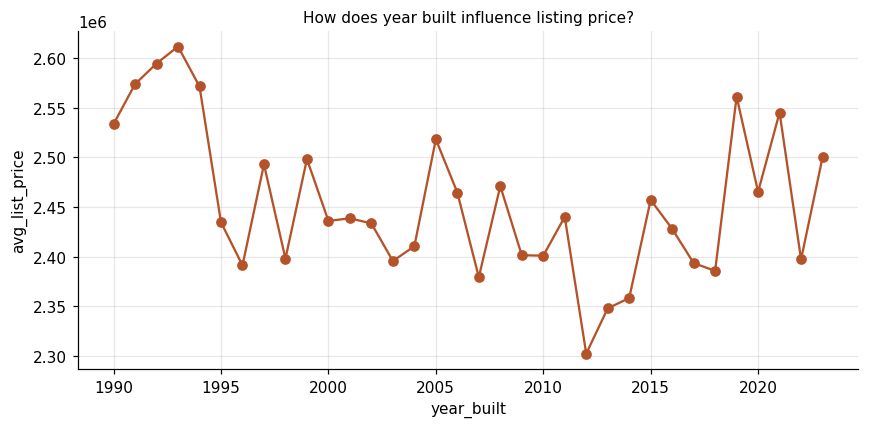

In [24]:
ax = r.plot(x="year_built", y="avg_list_price", marker="o", color=BRICK, legend=False)
ax.set_title("How does year built influence listing price?", fontsize=10); ax.set_ylabel("avg_list_price")
save("q08_year_built_price")

**Answer:** No premium for new construction: homes built 1990-1994 list highest ($2.58M average), later 5-year cohorts sit between $2.37M and $2.48M.

#### Q09. Which cities have the highest average property prices?

In [25]:
r = run("Q09")
r

Q09. Which cities have the highest average property prices?

WITH ordered AS (
    SELECT city, price,
           ROW_NUMBER() OVER (PARTITION BY city ORDER BY price) AS rn,
           COUNT(*)     OVER (PARTITION BY city)                AS n
    FROM listings
),
median AS (
    SELECT city, ROUND(AVG(price), 2) AS median_list_price
    FROM ordered
    WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
    GROUP BY city
)
SELECT RANK() OVER (ORDER BY AVG(l.price) DESC) AS price_rank,
       l.city,
       ROUND(AVG(l.price), 2)  AS avg_list_price,
       m.median_list_price,
       ROUND(MAX(l.price), 2)  AS max_list_price
FROM listings l
JOIN median m ON m.city = l.city
GROUP BY l.city
ORDER BY price_rank 



,price_rank,city,avg_list_price,median_list_price,max_list_price
0,1,New York,"2,493,319.74","2,446,518.63","4,998,508.49"
1,2,Phoenix,"2,459,961.76","2,397,597.97","4,999,863.52"
2,3,Los Angeles,"2,442,418.31","2,380,929.35","4,999,463.77"
3,4,Houston,"2,436,811.00","2,347,582.06","4,998,687.21"
4,5,Chicago,"2,430,677.90","2,351,084.47","4,997,593.10"


**Answer:** New York ranks first on both average ($2.49M) and median ($2.45M) price; the ranking is the same on either measure.

#### Q10. How are properties distributed across price buckets?

In [26]:
r = run("Q10")
r

Q10. How are properties distributed across price buckets?

SELECT CASE WHEN price < 1000000 THEN '1. Under $1M'
            WHEN price < 2000000 THEN '2. $1M-2M'
            WHEN price < 3000000 THEN '3. $2M-3M'
            WHEN price < 4000000 THEN '4. $3M-4M'
            ELSE '5. $4M+' END                                     AS price_bucket,
       COUNT(*)                                                     AS listings,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM listings), 2) AS pct_of_listings
FROM listings
GROUP BY price_bucket
ORDER BY price_bucket 



,price_bucket,listings,pct_of_listings
0,1. Under $1M,4269,20.14
1,2. $1M-2M,4800,22.64
2,3. $2M-3M,4025,18.99
3,4. $3M-4M,4083,19.26
4,5. $4M+,4023,18.98


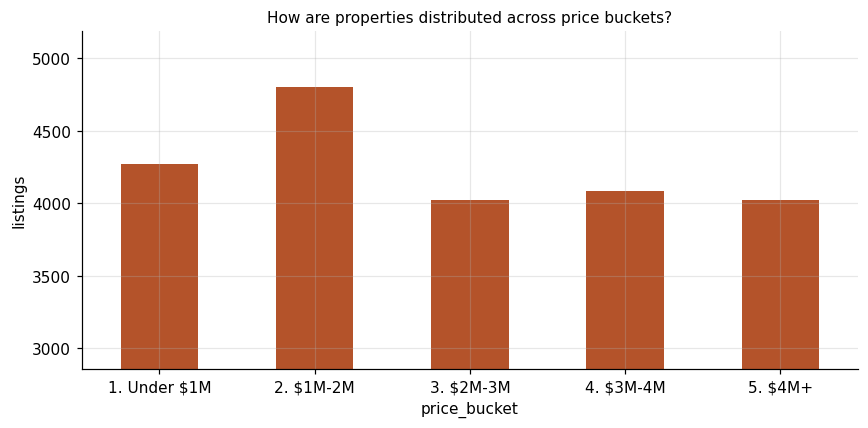

In [27]:
ax = r.plot.bar(x="price_bucket", y="listings", color=BRICK, legend=False, rot=0)
lo, hi = r["listings"].min(), r["listings"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("How are properties distributed across price buckets?", fontsize=10); ax.set_ylabel("listings")
save("q10_price_buckets")

**Answer:** Listings are spread almost evenly across the five $1M-wide buckets (19-23% each); $1M-2M is the largest.

### Sales & Market

#### Q11. What is the average days on market by city?

In [28]:
r = run("Q11")
r

Q11. What is the average days on market by city?

SELECT l.city,
       COUNT(*)                          AS sales,
       ROUND(AVG(s.days_on_market), 1)   AS avg_days_on_market
FROM sales s
JOIN listings l ON l.listing_id = s.listing_id
GROUP BY l.city
ORDER BY avg_days_on_market 



,city,sales,avg_days_on_market
0,Houston,131,58.50
1,Phoenix,168,59.70
2,New York,137,60.80
3,Chicago,156,64.30
4,Los Angeles,128,65.10


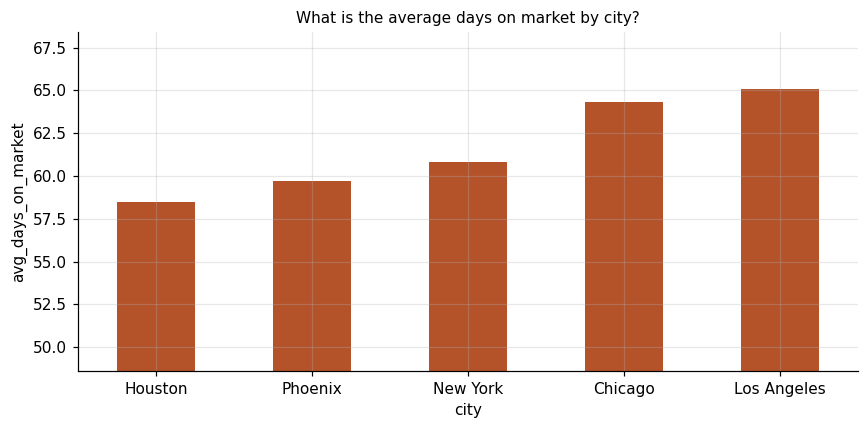

In [29]:
ax = r.plot.bar(x="city", y="avg_days_on_market", color=BRICK, legend=False, rot=0)
lo, hi = r["avg_days_on_market"].min(), r["avg_days_on_market"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("What is the average days on market by city?", fontsize=10); ax.set_ylabel("avg_days_on_market")
save("q11_days_on_market_by_city")

**Answer:** Houston sells fastest (58.5 days on average) and Los Angeles slowest (65.1 days).

#### Q12. Which property types sell the fastest?

In [30]:
r = run("Q12")
r

Q12. Which property types sell the fastest?

SELECT l.property_type,
       COUNT(*)                          AS sales,
       ROUND(AVG(s.days_on_market), 1)   AS avg_days_on_market,
       MIN(s.days_on_market)             AS fastest_sale_days
FROM sales s
JOIN listings l ON l.listing_id = s.listing_id
GROUP BY l.property_type
ORDER BY avg_days_on_market 



,property_type,sales,avg_days_on_market,fastest_sale_days
0,House,190,58.30,5
1,Apartment,176,60.60,5
2,Townhouse,167,61.00,5
3,Condo,187,66.50,5


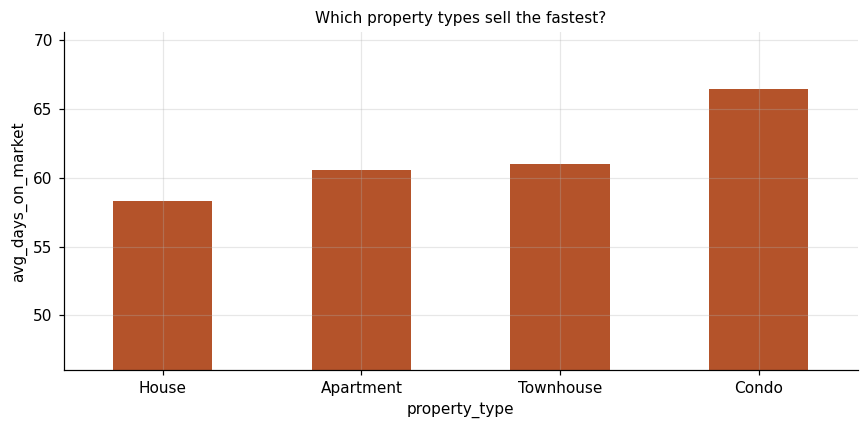

In [31]:
ax = r.plot.bar(x="property_type", y="avg_days_on_market", color=BRICK, legend=False, rot=0)
lo, hi = r["avg_days_on_market"].min(), r["avg_days_on_market"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("Which property types sell the fastest?", fontsize=10); ax.set_ylabel("avg_days_on_market")
save("q12_days_on_market_by_type")

**Answer:** Houses sell fastest (58.3 days); condos take the longest (66.5 days), about 8 days more.

#### Q13. What percentage of properties are sold above listing price?

In [32]:
r = run("Q13")
r

Q13. What percentage of properties are sold above listing price?

SELECT CASE WHEN s.sale_price > l.price THEN 'Above list price'
            WHEN s.sale_price = l.price THEN 'At list price'
            ELSE 'Below list price' END                            AS outcome,
       COUNT(*)                                                     AS sales,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM sales), 2)    AS pct_of_sales
FROM sales s
JOIN listings l ON l.listing_id = s.listing_id
GROUP BY outcome
ORDER BY sales DESC 



,outcome,sales,pct_of_sales
0,Below list price,365,50.69
1,Above list price,355,49.31


**Answer:** 49.3% of sales closed above the listing price and 50.7% below: pricing is close to fair value.

#### Q14. What is the sale-to-list price ratio by city?

In [33]:
r = run("Q14")
r

Q14. What is the sale-to-list price ratio by city?

SELECT l.city,
       COUNT(*)                                     AS sales,
       ROUND(AVG(s.sale_price / l.price), 4)        AS avg_sale_to_list_ratio,
       ROUND(SUM(s.sale_price) / SUM(l.price), 4)   AS total_sale_to_list_ratio
FROM sales s
JOIN listings l ON l.listing_id = s.listing_id
GROUP BY l.city
ORDER BY avg_sale_to_list_ratio DESC 



,city,sales,avg_sale_to_list_ratio,total_sale_to_list_ratio
0,Chicago,156,1.00,1.00
1,Houston,131,1.00,1.00
2,Los Angeles,128,1.00,1.00
3,New York,137,1.00,1.00
4,Phoenix,168,1.00,1.00


**Answer:** Sale-to-list ratios sit within 0.2% of 1.00 in every city; Chicago is the only city slightly above list (1.0015).

#### Q15. Which listings took more than 90 days to sell?

In [34]:
r = run("Q15")
print(f"{len(r):,} rows")
r.head(10)

Q15. Which listings took more than 90 days to sell?

SELECT s.listing_id, l.city, l.property_type, l.price AS list_price, s.sale_price,
       l.date_listed, s.date_sold, s.days_on_market
FROM sales s
JOIN listings l ON l.listing_id = s.listing_id
WHERE s.days_on_market > 90
ORDER BY s.days_on_market DESC, s.listing_id 

188 rows


,listing_id,city,property_type,list_price,sale_price,date_listed,date_sold,days_on_market
0,L00067,Chicago,Apartment,"293,562.99","286,681.00",2024-02-29,2024-06-28,120
1,L00157,Phoenix,Townhouse,"710,815.00","707,140.98",2023-04-29,2023-08-27,120
2,L00179,Chicago,Condo,"971,345.99","1,017,871.01",2023-08-30,2023-12-28,120
3,L00259,Phoenix,Apartment,"1,513,413.99","1,577,127.00",2023-05-20,2023-09-17,120
4,L00287,Houston,Townhouse,"1,724,170.00","1,769,308.00",2023-12-14,2024-04-12,120
5,L00057,Phoenix,Condo,"646,864.99","665,657.00",2023-12-09,2024-04-06,119
6,L00078,Los Angeles,House,"149,627.00","152,524.01",2023-07-24,2023-11-20,119
7,L00271,New York,House,"1,013,679.01","970,384.01",2023-09-26,2024-01-23,119
8,L00348,New York,Condo,"1,969,257.99","2,031,708.00",2024-03-11,2024-07-08,119
9,L00351,Phoenix,Condo,"1,080,221.01","1,032,111.00",2023-11-10,2024-03-08,119


**Answer:** 188 of 720 sales (26%) took more than 90 days; the slowest took 120 days.

#### Q16. How does metro distance affect time on market?

In [35]:
r = run("Q16")
r

Q16. How does metro distance affect time on market?

SELECT CASE WHEN pa.metro_distance_km < 2  THEN '1. Under 2 km'
            WHEN pa.metro_distance_km < 5  THEN '2. 2-5 km'
            WHEN pa.metro_distance_km < 10 THEN '3. 5-10 km'
            ELSE '4. 10 km+' END            AS metro_distance,
       COUNT(*)                             AS sales,
       ROUND(AVG(s.days_on_market), 1)      AS avg_days_on_market
FROM sales s
JOIN property_attributes pa ON pa.listing_id = s.listing_id
GROUP BY metro_distance
ORDER BY metro_distance 



,metro_distance,sales,avg_days_on_market
0,1. Under 2 km,153,64.70
1,2. 2-5 km,265,60.90
2,3. 5-10 km,302,60.70


**Answer:** Homes within 2 km of a metro took the longest to sell (64.7 days vs about 61 elsewhere); no sold home is more than 8 km from a metro.

#### Q17. What is the monthly sales trend?

In [36]:
r = run("Q17")
r

Q17. What is the monthly sales trend?

SELECT strftime('%Y-%m', date_sold)   AS month,
       COUNT(*)                       AS sales,
       ROUND(SUM(sale_price), 2)      AS revenue,
       ROUND(AVG(sale_price), 2)      AS avg_sale_price
FROM sales
GROUP BY month
ORDER BY month 



,month,sales,revenue,avg_sale_price
0,2023-01,7,"5,298,400.96","756,914.42"
1,2023-02,17,"15,945,070.02","937,945.30"
2,2023-03,20,"19,995,066.06","999,753.30"
3,2023-04,36,"44,208,249.99","1,228,006.94"
4,2023-05,45,"51,385,673.97","1,141,903.87"
5,2023-06,31,"29,643,443.03","956,240.10"
6,2023-07,48,"56,000,209.96","1,166,671.04"
7,2023-08,50,"55,050,662.07","1,101,013.24"
8,2023-09,46,"49,868,704.96","1,084,102.28"
9,2023-10,64,"70,202,528.99","1,096,914.52"


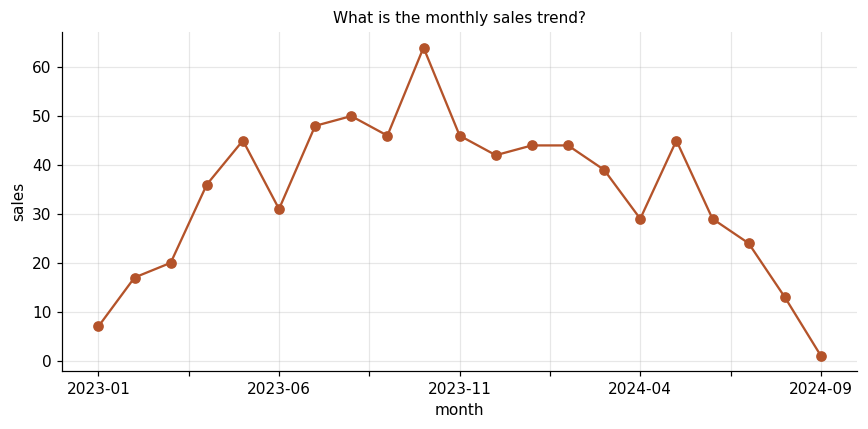

In [37]:
ax = r.plot(x="month", y="sales", marker="o", color=BRICK, legend=False)
ax.set_title("What is the monthly sales trend?", fontsize=10); ax.set_ylabel("sales")
save("q17_monthly_sales")

**Answer:** Sales ramp up through 2023, peak in October 2023 (64 sales), and taper off after mid-2024.

#### Q18. Which properties are currently unsold?

In [38]:
r = run("Q18")
print(f"{len(r):,} rows")
r.head(10)

Q18. Which properties are currently unsold?

SELECT l.listing_id, l.city, l.property_type, l.price, l.area_sqft, l.date_listed, l.agent_id
FROM listings l
WHERE NOT EXISTS (SELECT 1 FROM sales s WHERE s.listing_id = l.listing_id)
ORDER BY l.date_listed, l.listing_id 

20,480 rows


,listing_id,city,property_type,price,area_sqft,date_listed,agent_id
0,L01460,Los Angeles,Townhouse,"3,049,053.39","3,416.27",2023-01-01,A0034
1,L02158,Chicago,Condo,"3,447,822.35","5,391.60",2023-01-01,A0035
2,L04325,New York,Apartment,"737,399.70","6,265.78",2023-01-01,A0014
3,L04378,Phoenix,Apartment,"3,976,515.39","5,091.39",2023-01-01,A0013
4,L07239,Los Angeles,Townhouse,"3,611,871.66","7,323.45",2023-01-01,A0043
5,L07425,Chicago,House,"3,325,174.11","9,842.94",2023-01-01,A0041
6,L08024,Phoenix,Condo,"3,305,636.54","4,479.84",2023-01-01,A0045
7,L08311,New York,Apartment,"2,713,607.49","9,060.33",2023-01-01,A0013
8,L08520,Chicago,Condo,"4,070,408.07","6,273.11",2023-01-01,A0011
9,L08677,Chicago,Condo,"1,670,092.09","3,404.30",2023-01-01,A0012


**Answer:** 20,480 of 21,200 listings (96.6%) are still unsold. All 720 sales come from the first 1,200 listings (L00001-L01200).

### Agent Performance

#### Q19. Which agents have closed the most sales?

In [39]:
r = run("Q19")
r

Q19. Which agents have closed the most sales?

SELECT a.agent_id, a.name,
       COUNT(s.sale_id) AS sales_closed
FROM agents a
JOIN listings l ON l.agent_id   = a.agent_id
JOIN sales s    ON s.listing_id = l.listing_id
GROUP BY a.agent_id
ORDER BY sales_closed DESC, a.agent_id
LIMIT 10 



,agent_id,name,sales_closed
0,A0042,Agent A0042,25
1,A0011,Agent A0011,24
2,A0014,Agent A0014,21
3,A0035,Agent A0035,21
4,A0043,Agent A0043,20
5,A0046,Agent A0046,20
6,A0007,Agent A0007,19
7,A0048,Agent A0048,19
8,A0027,Agent A0027,18
9,A0029,Agent A0029,18


**Answer:** Agent A0042 closed the most sales (25), followed by A0011 (24).

#### Q20. Who are the top agents by total sales revenue?

In [40]:
r = run("Q20")
r

Q20. Who are the top agents by total sales revenue?

SELECT a.agent_id, a.name,
       COUNT(s.sale_id)              AS sales_closed,
       ROUND(SUM(s.sale_price), 2)   AS total_revenue
FROM agents a
JOIN listings l ON l.agent_id   = a.agent_id
JOIN sales s    ON s.listing_id = l.listing_id
GROUP BY a.agent_id
ORDER BY total_revenue DESC
LIMIT 10 



,agent_id,name,sales_closed,total_revenue
0,A0011,Agent A0011,24,"27,882,272.01"
1,A0042,Agent A0042,25,"27,191,605.99"
2,A0043,Agent A0043,20,"24,102,418.01"
3,A0035,Agent A0035,21,"22,725,751.98"
4,A0014,Agent A0014,21,"22,034,008.02"
5,A0046,Agent A0046,20,"21,335,804.97"
6,A0048,Agent A0048,19,"21,186,305.99"
7,A0027,Agent A0027,18,"21,099,696.97"
8,A0009,Agent A0009,17,"20,279,274.94"
9,A0029,Agent A0029,18,"19,586,498.01"


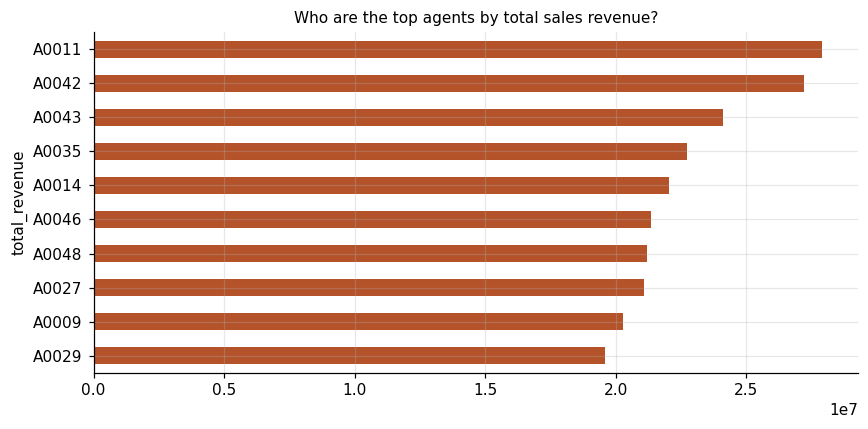

In [41]:
ax = r.plot.barh(x="agent_id", y="total_revenue", color=BRICK, legend=False); ax.invert_yaxis()
ax.set_title("Who are the top agents by total sales revenue?", fontsize=10); ax.set_ylabel("total_revenue")
save("q20_top_agents_revenue")

**Answer:** Agent A0011 generated the most revenue ($27.9M from 24 sales), just ahead of A0042 ($27.2M).

#### Q21. Which agents close deals fastest?

In [42]:
r = run("Q21")
r

Q21. Which agents close deals fastest?

SELECT a.agent_id, a.name,
       COUNT(s.sale_id)                  AS sales_closed,
       ROUND(AVG(s.days_on_market), 1)   AS avg_days_on_market,
       a.avg_closing_days                AS profile_avg_closing_days
FROM agents a
JOIN listings l ON l.agent_id   = a.agent_id
JOIN sales s    ON s.listing_id = l.listing_id
GROUP BY a.agent_id
HAVING COUNT(s.sale_id) >= 5
ORDER BY avg_days_on_market, a.agent_id
LIMIT 10 



,agent_id,name,sales_closed,avg_days_on_market,profile_avg_closing_days
0,A0044,Agent A0044,8,36.90,35
1,A0013,Agent A0013,7,42.40,65
2,A0037,Agent A0037,12,44.50,77
3,A0002,Agent A0002,8,45.50,82
4,A0008,Agent A0008,11,46.60,72
5,A0017,Agent A0017,14,48.60,58
6,A0026,Agent A0026,12,49.50,42
7,A0012,Agent A0012,11,50.60,82
8,A0010,Agent A0010,15,51.10,90
9,A0043,Agent A0043,20,52.40,89


**Answer:** Among agents with at least 5 sales, A0044 is fastest (36.9 days on market on average).

#### Q22. Does experience correlate with deals closed?

In [43]:
r = run("Q22")
r

Q22. Does experience correlate with deals closed?

SELECT CASE WHEN experience_years <= 5  THEN '1. 0-5 yrs'
            WHEN experience_years <= 10 THEN '2. 6-10 yrs'
            WHEN experience_years <= 15 THEN '3. 11-15 yrs'
            WHEN experience_years <= 20 THEN '4. 16-20 yrs'
            ELSE '5. 21+ yrs' END                AS experience,
       COUNT(*)                                  AS agents,
       ROUND(AVG(deals_closed_lifetime), 1)      AS avg_deals_closed,
       ROUND(AVG(sales), 1)                      AS avg_sales_in_dataset
FROM v_agent_performance
GROUP BY experience
ORDER BY experience 



,experience,agents,avg_deals_closed,avg_sales_in_dataset
0,1. 0-5 yrs,8,108.90,16.10
1,2. 6-10 yrs,5,123.20,14.20
2,3. 11-15 yrs,10,141.10,13.50
3,4. 16-20 yrs,17,133.50,12.70
4,5. 21+ yrs,10,166.40,16.90


**Answer:** Weak positive link: agents with 21+ years average 166 lifetime deals vs 109 for 0-5 years, but the trend is not steady and sales in this data set don't follow it.

#### Q23. Do agents with higher ratings close deals faster?

In [44]:
r = run("Q23")
r

Q23. Do agents with higher ratings close deals faster?

SELECT CASE WHEN rating < 3.5 THEN '1. Below 3.5'
            WHEN rating < 4.0 THEN '2. 3.5-3.9'
            WHEN rating < 4.5 THEN '3. 4.0-4.4'
            ELSE '4. 4.5-5.0' END                AS rating_band,
       COUNT(*)                                  AS agents,
       ROUND(AVG(avg_closing_days), 1)           AS avg_closing_days,
       ROUND(AVG(avg_days_on_market), 1)         AS avg_days_on_market_in_dataset
FROM v_agent_performance
GROUP BY rating_band
ORDER BY rating_band 



,rating_band,agents,avg_closing_days,avg_days_on_market_in_dataset
0,1. Below 3.5,12,56.80,60.10
1,2. 3.5-3.9,12,67.70,60.40
2,3. 4.0-4.4,16,48.40,60.30
3,4. 4.5-5.0,10,51.70,62.40


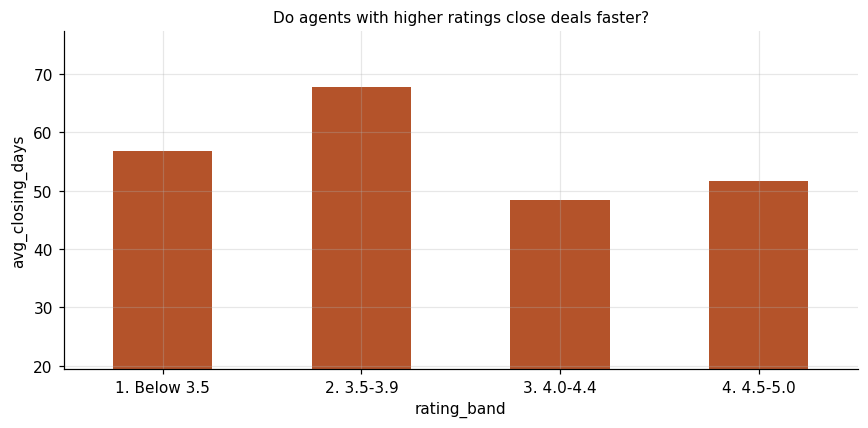

In [45]:
ax = r.plot.bar(x="rating_band", y="avg_closing_days", color=BRICK, legend=False, rot=0)
lo, hi = r["avg_closing_days"].min(), r["avg_closing_days"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("Do agents with higher ratings close deals faster?", fontsize=10); ax.set_ylabel("avg_closing_days")
save("q23_rating_vs_closing")

**Answer:** No: the 4.5-5.0 rated agents take about as long (51.7 days) as the 4.0-4.4 band (48.4); the slowest band is 3.5-3.9 (67.7).

#### Q24. What is the average commission earned by each agent?

In [46]:
r = run("Q24")
print(f"{len(r):,} rows")
r.head(10)

Q24. What is the average commission earned by each agent?

SELECT a.agent_id, a.name, a.commission_rate,
       COUNT(s.sale_id)                                              AS sales_closed,
       ROUND(AVG(s.sale_price * a.commission_rate / 100.0), 2)      AS avg_commission_per_sale,
       ROUND(SUM(s.sale_price * a.commission_rate / 100.0), 2)      AS total_commission
FROM agents a
JOIN listings l ON l.agent_id   = a.agent_id
JOIN sales s    ON s.listing_id = l.listing_id
GROUP BY a.agent_id
ORDER BY avg_commission_per_sale DESC 

50 rows


,agent_id,name,commission_rate,sales_closed,avg_commission_per_sale,total_commission
0,A0009,Agent A0009,2.85,17,"33,997.61","577,959.34"
1,A0002,Agent A0002,2.20,8,"32,326.16","258,609.25"
2,A0035,Agent A0035,2.96,21,"32,032.49","672,682.26"
3,A0012,Agent A0012,2.37,11,"31,737.61","349,113.68"
4,A0030,Agent A0030,2.79,11,"31,665.09","348,316.02"
5,A0018,Agent A0018,2.63,13,"31,438.36","408,698.74"
6,A0031,Agent A0031,2.51,13,"30,358.05","394,654.65"
7,A0050,Agent A0050,2.56,17,"28,564.40","485,594.83"
8,A0017,Agent A0017,2.14,14,"28,406.74","397,694.41"
9,A0024,Agent A0024,2.95,14,"27,805.90","389,282.53"


**Answer:** Average commission per sale ranges up to $34.0k (A0009, at a 2.85% rate). Total commission is driven mostly by sales volume.

#### Q25. Which agents currently have the most active listings?

In [47]:
r = run("Q25")
r

Q25. Which agents currently have the most active listings?

SELECT a.agent_id, a.name,
       COUNT(*) AS active_listings
FROM agents a
JOIN v_active_listings al ON al.agent_id = a.agent_id
GROUP BY a.agent_id
ORDER BY active_listings DESC, a.agent_id
LIMIT 10 



,agent_id,name,active_listings
0,A0023,Agent A0023,446
1,A0011,Agent A0011,439
2,A0008,Agent A0008,438
3,A0042,Agent A0042,435
4,A0014,Agent A0014,432
5,A0044,Agent A0044,430
6,A0020,Agent A0020,426
7,A0012,Agent A0012,425
8,A0015,Agent A0015,425
9,A0048,Agent A0048,425


**Answer:** Agent A0023 has the most active listings (446); the top 10 are all within 446-425.

### Buyer & Financing

#### Q26. What percentage of buyers are investors vs end users?

In [48]:
r = run("Q26")
r

Q26. What percentage of buyers are investors vs end users?

SELECT buyer_type,
       COUNT(*)                                                     AS buyers,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM buyers), 2)   AS pct_of_buyers
FROM buyers
GROUP BY buyer_type
ORDER BY buyers DESC 



,buyer_type,buyers,pct_of_buyers
0,End User,10020,50.10
1,Investor,9980,49.90


**Answer:** Buyers split evenly: 50.1% end users and 49.9% investors.

#### Q27. Which cities have the highest loan uptake rate?

In [49]:
r = run("Q27")
r

Q27. Which cities have the highest loan uptake rate?

SELECT l.city,
       COUNT(*)                            AS buyers,
       SUM(b.loan_taken)                   AS buyers_with_loan,
       ROUND(AVG(b.loan_taken) * 100, 2)   AS loan_uptake_pct
FROM buyers b
JOIN sales s    ON s.sale_id    = b.sale_id
JOIN listings l ON l.listing_id = s.listing_id
GROUP BY l.city
ORDER BY loan_uptake_pct DESC 



,city,buyers,buyers_with_loan,loan_uptake_pct
0,Los Angeles,3552,1811,50.99
1,Chicago,4327,2188,50.57
2,New York,3809,1913,50.22
3,Houston,3639,1809,49.71
4,Phoenix,4673,2313,49.50


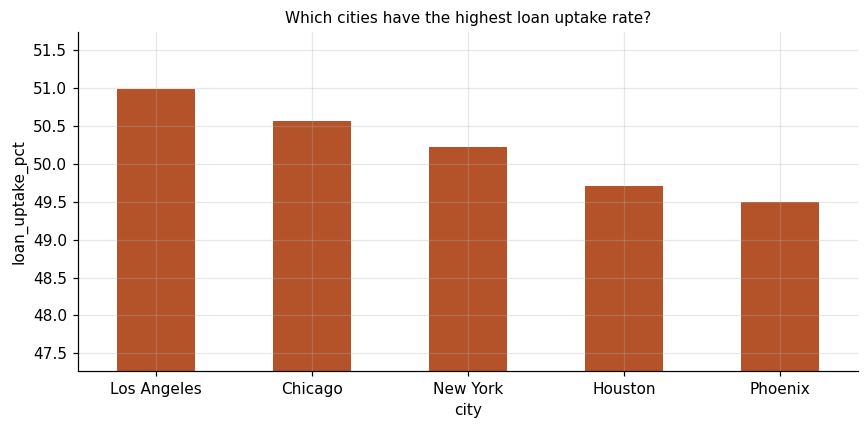

In [50]:
ax = r.plot.bar(x="city", y="loan_uptake_pct", color=BRICK, legend=False, rot=0)
lo, hi = r["loan_uptake_pct"].min(), r["loan_uptake_pct"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("Which cities have the highest loan uptake rate?", fontsize=10); ax.set_ylabel("loan_uptake_pct")
save("q27_loan_uptake_by_city")

**Answer:** Loan uptake is about 50% everywhere, from 49.5% (Phoenix) to 51.0% (Los Angeles).

#### Q28. What is the average loan amount by buyer type?

In [51]:
r = run("Q28")
r

Q28. What is the average loan amount by buyer type?

SELECT buyer_type,
       COUNT(*)                      AS loans,
       ROUND(AVG(loan_amount), 2)    AS avg_loan_amount
FROM buyers
WHERE loan_taken = 1
GROUP BY buyer_type
ORDER BY avg_loan_amount DESC 



,buyer_type,loans,avg_loan_amount
0,Investor,5035,"5,211,545.97"
1,End User,4999,"5,210,307.45"


**Answer:** Investors and end users borrow almost the same on average (about $5.21M).

#### Q29. Which payment mode is most commonly used?

In [52]:
r = run("Q29")
r

Q29. Which payment mode is most commonly used?

SELECT payment_mode,
       COUNT(*)                                                     AS buyers,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM buyers), 2)   AS pct_of_buyers
FROM buyers
GROUP BY payment_mode
ORDER BY buyers DESC 



,payment_mode,buyers,pct_of_buyers
0,Cash,5088,25.44
1,UPI,5012,25.06
2,Cheque,4951,24.75
3,Bank Transfer,4949,24.75


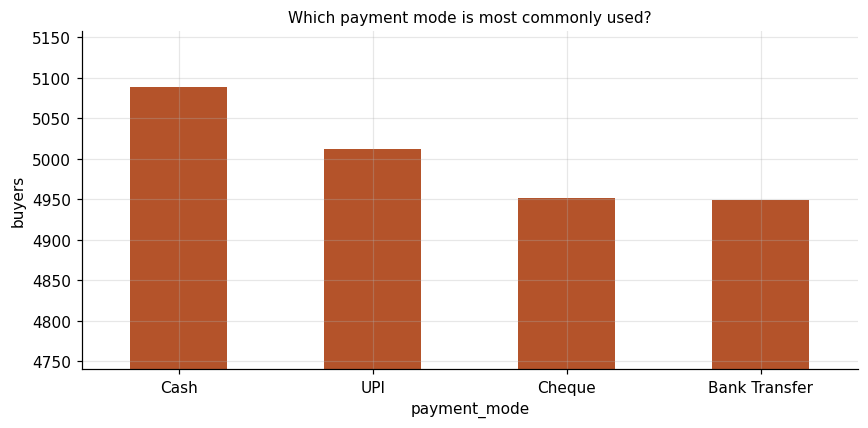

In [53]:
ax = r.plot.bar(x="payment_mode", y="buyers", color=BRICK, legend=False, rot=0)
lo, hi = r["buyers"].min(), r["buyers"].max()
ax.set_ylim(max(0, lo - (hi - lo) * 1.5), hi + (hi - lo) * 0.5) if hi > lo else None
ax.set_title("Which payment mode is most commonly used?", fontsize=10); ax.set_ylabel("buyers")
save("q29_payment_mode")

**Answer:** Cash is used most (25.4%), but all four payment modes are within 0.7 points of each other.

#### Q30. Do loan-backed purchases take longer to close?

In [54]:
r = run("Q30")
r

Q30. Do loan-backed purchases take longer to close?

SELECT CASE b.loan_taken WHEN 1 THEN 'Loan-backed' ELSE 'No loan' END AS financing,
       COUNT(*)                            AS buyers,
       ROUND(AVG(s.days_on_market), 2)     AS avg_days_on_market
FROM buyers b
JOIN sales s ON s.sale_id = b.sale_id
GROUP BY b.loan_taken
ORDER BY avg_days_on_market DESC 



,financing,buyers,avg_days_on_market
0,Loan-backed,10034,62.15
1,No loan,9966,61.07


**Answer:** Loan-backed purchases took about one day longer (62.2 vs 61.1 days on market): a negligible difference.

## 5. Key insights

1. **Prices are close to fair value.** 49% of homes sold above list and 51% below; the sale-to-list ratio is within 0.2% of 1.00 in every city.
2. **New York is the most expensive city** ($2.49M average list price) and Chicago the cheapest, but the spread is only 2.6%.
3. **Houses sell fastest** (58 days on market on average) and condos slowest (67 days). Houston turns over fastest of the cities (58.5 days), Los Angeles slowest (65.1).
4. **Location and amenities barely move prices.** There is no metro premium (homes 10 km+ away list *higher*), furnishing adds about 1%, and parking + power backup about 4% on sale price.
5. **Sales peaked in October 2023** (64 sales) and declined through 2024; 26% of sales took more than 90 days.
6. **Agent ratings don't predict speed**, and experience is only weakly linked to lifetime deals. Sales volume, not commission rate, drives total commission.
7. **Buyers split 50/50** between investors and end users; about half take a loan, loan uptake is about 50% in every city, and the four payment modes are used almost equally.
8. **The data is synthetic.** Most attributes are uniformly distributed and independent of price, so many "effects" are within a few percent. The coordinates, the two listing populations and the buyer/loan figures should not be used for real decisions.